In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.subsampling import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../data/before_continuous/data_treated_nopr.csv")

diagnosis_variables = []

with open("../data/before_continuous/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/before_continuous/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

# cols_to_remove = ['Type of 1st intervention', 'Axillary operation', 'SLN procedure']

# removed = []
# for c in cols_to_remove:
#     if c in diagnosis_variables:
#         diagnosis_variables.remove(c)
#         removed.append(c)

# # Also drop these columns from the dataframe so they won't appear in survival_dataset
# if removed:
#     dataset = dataset.drop(columns=removed, errors='ignore')

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [5]:
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=survival_dataset['Regional LN recurrence'])

train_index, test_index = next(cv)

In [6]:
for train_idx, val_idx in cv:
    print("Train events:", survival_dataset.iloc[train_idx]["Regional LN recurrence"].sum())
    print("Val events:", survival_dataset.iloc[val_idx]["Regional LN recurrence"].sum())

Train events: 27.0
Val events: 6.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0
Train events: 26.0
Val events: 7.0


In [7]:
print("Train events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

Train events: 27.0
Test events: 6.0


In [8]:
subsampling = survival_dataset.iloc[train_index].copy()

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
sgkf_1 = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

In [9]:
l1_ratio = 1
model = CoxnetSurvivalAnalysis(l1_ratio=l1_ratio)
alphas = np.logspace(-3.5, -2, 20)
(alphas)
list_alphas = alphas.tolist()
alphas = pd.DataFrame(list_alphas, columns=['Alphas'])

In [10]:
# Define your hyperparameter ranges
alpha_range = np.logspace(-3, -1.8, 10)  # 20 alpha values
l1_ratio_range = [1.0, 0.8, 0.5, 0.1, 0.01, 0.001]  # From Lasso to Ridge
controls_per_case_range = [7, 10, 15, 20]  # Different subsampling ratios

metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

# Run grid search
results, best_params, summary_df = subsampling_grid_search(
    dataset=survival_dataset,
    X=x_train,
    y=y_train,
    cv_folds=sgkf_1,
    alpha_range=alpha_range,
    l1_ratio_range=l1_ratio_range,
    controls_per_case_range=controls_per_case_range,
    metrics=metrics,
    feature_columns=feature_columns,
    scaler=StandardScaler(),
    verbose=True
)

SUBSAMPLING GRID SEARCH
Controls per case: [7, 10, 15, 20]
L1 ratios: [1.0, 0.8, 0.5, 0.1, 0.01, 0.001]
Alphas: 10 values from 1.00e-03 to 1.58e-02
Total combinations: 240

[1/240] controls=7, l1=1.000, alpha=1.00e-03 (elapsed: 0.0min, est. remaining: 0.0min)
⚠️  Info: 4 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 63 67]
   Features after removal: 65 (removed 4)
⚠️  Info: 4 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 63 67]
   Features after removal: 65 (removed 4)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[2/240] controls=7, l1=1.000, alpha=1.36e-03 (elapsed: 0.2min, est. remaining: 22.8min)
⚠️  Info: 4 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 63 67]
   Features after removal: 65 (removed 4)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[3/240] controls=7, l1=1.000, alpha=1.85e-03 (elapsed: 0.3min, est. remaining: 21.6min)
⚠️  Info: 4 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 63 67]
   Features after removal: 65 (removed 4)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


... (31 outputs left out)

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[184/240] controls=20, l1=1.000, alpha=2.51e-03 (elapsed: 27.2min, est. remaining: 8.3min)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 63 67]
   Features after removal: 66 (removed 3)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 67]
   Features after removal: 66 (removed 3)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 67]
   Features after removal: 66 (removed 3)
⚠️  Info: 1 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [67]
   Fe

c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


  ⚠️ Configuration failed: Input estimate contains NaN.
[186/240] controls=20, l1=1.000, alpha=4.64e-03 (elapsed: 27.6min, est. remaining: 8.0min)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 63 67]
   Features after removal: 66 (removed 3)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 63 67]
   Features after removal: 66 (removed 3)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 67]
   Features after removal: 66 (removed 3)
⚠️  Info: 3 constant features detected with StandardScaler.
   Removing these features to avoid NaN values (StandardScaler divides by std=0).
   Constant feature indices: [11 57 67]

In [13]:
# Extract best parameters for each metric from grid search
# EXCLUDE configurations that had ANY failed folds (NaN values in individual folds)

# First, identify configurations where ANY fold has NaN values
configs_with_nan_folds = set()

for n_controls in results.keys():
    for l1_ratio in results[n_controls].keys():
        for alpha in results[n_controls][l1_ratio].keys():
            results_df = results[n_controls][l1_ratio][alpha]
            
            # Check if any fold has NaN in any metric
            fold_rows = results_df.loc[results_df.index.str.startswith('Fold_')]
            
            # If any fold has any NaN value, mark this config as invalid
            if fold_rows.isna().any().any():
                configs_with_nan_folds.add((n_controls, l1_ratio, alpha))

print(f"Configurations with at least one failed fold: {len(configs_with_nan_folds)}")

# Filter summary_df to exclude configurations with ANY failed folds
def is_valid_config(row):
    return (row['n_controls'], row['l1_ratio'], row['alpha']) not in configs_with_nan_folds

valid_summary_df = summary_df[summary_df.apply(is_valid_config, axis=1)].copy()

print(f"Total configurations: {len(summary_df)}")
print(f"Valid configurations (all folds successful): {len(valid_summary_df)}")
print(f"Excluded configurations (had failed folds): {len(summary_df) - len(valid_summary_df)}")

best_params = {}
for metric in ['c-index', 'c-index-ipcw', 'brier_2yr', 'brier_5yr', 'brier_10yr']:
    metric_df = valid_summary_df[valid_summary_df['metric'] == metric]
    
    if len(metric_df) == 0:
        print(f"\n⚠️  WARNING: No valid configurations for {metric}!")
        continue
    
    # For Brier scores, lower is better
    if metric.startswith('brier'):
        best_idx = metric_df['mean'].idxmin()
    else:
        best_idx = metric_df['mean'].idxmax()
    
    best_row = metric_df.loc[best_idx]
    
    best_params[metric] = {
        'n_controls': best_row['n_controls'],
        'l1_ratio': best_row['l1_ratio'],
        'alpha': best_row['alpha'],
        'mean': best_row['mean'],
        'std': best_row['std']
    }

# Access best parameters
print("\n" + "="*80)
print("BEST PARAMETERS FROM GRID SEARCH (only fully successful configurations)")
print("="*80)
for metric, params in best_params.items():
    print(f"\n{metric.upper()}:")
    print(f"  n_controls_per_case: {params['n_controls']}")
    print(f"  l1_ratio: {params['l1_ratio']:.4f}")
    print(f"  alpha: {params['alpha']:.4e}")
    print(f"  Score: {params['mean']:.4f} ± {params['std']:.4f}")

print("\n" + "="*80)
print("CHECKING FOR CONFIGURATIONS WITH FAILED FOLDS")
print("="*80)

# Show which unique configurations had failures
print(f"\nUnique configurations with failed folds: {len(configs_with_nan_folds)}")
if len(configs_with_nan_folds) > 0:
    print("\nConfigurations excluded from best parameter selection:")
    for n_controls, l1_ratio, alpha in sorted(configs_with_nan_folds):
        print(f"  n_controls={n_controls}, l1_ratio={l1_ratio:.3f}, alpha={alpha:.2e}")

# Also check if any specific results DataFrames have NaN in individual folds
print("\n" + "="*80)
print("DETAILED FOLD-LEVEL CHECK FOR BEST PARAMETERS")
print("="*80)

for metric, params in best_params.items():
    n_controls = params['n_controls']
    l1_ratio = params['l1_ratio']
    alpha = params['alpha']
    
    print(f"\n{metric.upper()} - Best Config (n_controls={n_controls}, l1={l1_ratio:.3f}, α={alpha:.2e}):")
    
    # Get the specific results DataFrame
    results_df = results[n_controls][l1_ratio][alpha]
    
    # Check for NaN in individual folds
    fold_rows = results_df.loc[results_df.index.str.startswith('Fold_')]
    nan_folds = fold_rows[fold_rows[metric].isna()]
    
    if len(nan_folds) > 0:
        print(f"  ❌ {len(nan_folds)} fold(s) returned NaN:")
        for fold_name in nan_folds.index:
            print(f"     {fold_name}")
    else:
        print(f"  ✅ All {len(fold_rows)} folds completed successfully")
        print(f"     Fold scores: {fold_rows[metric].values}")

print("\n" + "="*80)

Configurations with at least one failed fold: 159
Total configurations: 720
Valid configurations (all folds successful): 243
Excluded configurations (had failed folds): 477

⚠️  WARNING: No valid configurations for brier_2yr!

⚠️  WARNING: No valid configurations for brier_5yr!

⚠️  WARNING: No valid configurations for brier_10yr!

BEST PARAMETERS FROM GRID SEARCH (only fully successful configurations)

C-INDEX:
  n_controls_per_case: 10
  l1_ratio: 1.0000
  alpha: 4.6416e-03
  Score: 0.9164 ± 0.0551

C-INDEX-IPCW:
  n_controls_per_case: 10
  l1_ratio: 0.1000
  alpha: 1.1659e-02
  Score: 0.8565 ± 0.0996

CHECKING FOR CONFIGURATIONS WITH FAILED FOLDS

Unique configurations with failed folds: 159

Configurations excluded from best parameter selection:
  n_controls=7, l1_ratio=0.001, alpha=1.00e-03
  n_controls=7, l1_ratio=0.001, alpha=1.36e-03
  n_controls=7, l1_ratio=0.001, alpha=1.85e-03
  n_controls=7, l1_ratio=0.001, alpha=2.51e-03
  n_controls=7, l1_ratio=0.001, alpha=3.41e-03
  n_c

In [15]:
# Find best c-index-ipcw hyperparameters with lowest standard deviation
print("="*80)
print("BEST C-INDEX-IPCW HYPERPARAMETERS WITH LOWEST STD")
print("="*80)

# Filter for c-index-ipcw metric only and valid configurations
ipcw_valid = valid_summary_df[valid_summary_df['metric'] == 'c-index-ipcw'].copy()

if len(ipcw_valid) > 0:
    # Find configuration with minimum std
    min_std_idx = ipcw_valid['std'].idxmin()
    min_std_config = ipcw_valid.loc[min_std_idx]
    
    print(f"\nConfiguration with LOWEST standard deviation:")
    print(f"  n_controls_per_case: {int(min_std_config['n_controls'])}")
    print(f"  l1_ratio: {min_std_config['l1_ratio']:.4f}")
    print(f"  alpha: {min_std_config['alpha']:.4e}")
    print(f"  Mean: {min_std_config['mean']:.4f}")
    print(f"  Std:  {min_std_config['std']:.4f}")
    
    # Compare with best mean performance
    best_mean_idx = ipcw_valid['mean'].idxmax()
    best_mean_config = ipcw_valid.loc[best_mean_idx]
    
    print(f"\n" + "-"*80)
    print("COMPARISON: Lowest Std vs Highest Mean")
    print("-"*80)
    
    print(f"\nLowest Std configuration:")
    print(f"  n_controls={int(min_std_config['n_controls'])}, l1_ratio={min_std_config['l1_ratio']:.4f}, alpha={min_std_config['alpha']:.4e}")
    print(f"  Mean: {min_std_config['mean']:.4f}, Std: {min_std_config['std']:.4f}")
    
    print(f"\nHighest Mean configuration:")
    print(f"  n_controls={int(best_mean_config['n_controls'])}, l1_ratio={best_mean_config['l1_ratio']:.4f}, alpha={best_mean_config['alpha']:.4e}")
    print(f"  Mean: {best_mean_config['mean']:.4f}, Std: {best_mean_config['std']:.4f}")
    
    print(f"\nDifferences:")
    print(f"  Mean difference: {min_std_config['mean'] - best_mean_config['mean']:.4f}")
    print(f"  Std difference: {min_std_config['std'] - best_mean_config['std']:.4f}")
    
    # Get detailed fold-level results for lowest std config
    n_controls_min = int(min_std_config['n_controls'])
    l1_ratio_min = min_std_config['l1_ratio']
    alpha_min = min_std_config['alpha']
    
    print(f"\n" + "-"*80)
    print("DETAILED FOLD-LEVEL RESULTS FOR LOWEST STD CONFIGURATION")
    print("-"*80)
    
    results_df_min = results[n_controls_min][l1_ratio_min][alpha_min]
    fold_rows_min = results_df_min.loc[results_df_min.index.str.startswith('Fold_')]
    
    print(f"\nIndividual fold scores for c-index-ipcw:")
    for fold_name in fold_rows_min.index:
        fold_score = fold_rows_min.loc[fold_name, 'c-index-ipcw']
        if pd.isna(fold_score):
            print(f"  {fold_name}: NaN (failed)")
        else:
            print(f"  {fold_name}: {fold_score:.4f}")
    
    print(f"\nMean: {results_df_min.loc['Mean', 'c-index-ipcw']:.4f}")
    print(f"Std:  {results_df_min.loc['Std', 'c-index-ipcw']:.4f}")
    
    # Show other metrics for this configuration
    print(f"\nOther metrics for lowest std configuration:")
    print(f"  c-index: {results_df_min.loc['Mean', 'c-index']:.4f} ± {results_df_min.loc['Std', 'c-index']:.4f}")
    print(f"  int-brier-score: {results_df_min.loc['Mean', 'int-brier-score']:.4f} ± {results_df_min.loc['Std', 'int-brier-score']:.4f}")
    
else:
    print("\n⚠️  No valid c-index-ipcw configurations found!")

print("\n" + "="*80)

BEST C-INDEX-IPCW HYPERPARAMETERS WITH LOWEST STD

Configuration with LOWEST standard deviation:
  n_controls_per_case: 15
  l1_ratio: 0.0010
  alpha: 1.5849e-02
  Mean: 0.8499
  Std:  0.0843

--------------------------------------------------------------------------------
COMPARISON: Lowest Std vs Highest Mean
--------------------------------------------------------------------------------

Lowest Std configuration:
  n_controls=15, l1_ratio=0.0010, alpha=1.5849e-02
  Mean: 0.8499, Std: 0.0843

Highest Mean configuration:
  n_controls=10, l1_ratio=0.1000, alpha=1.1659e-02
  Mean: 0.8565, Std: 0.0996

Differences:
  Mean difference: -0.0065
  Std difference: -0.0153

--------------------------------------------------------------------------------
DETAILED FOLD-LEVEL RESULTS FOR LOWEST STD CONFIGURATION
--------------------------------------------------------------------------------

Individual fold scores for c-index-ipcw:
  Fold_1: 0.7632
  Fold_2: 0.9577
  Fold_3: 0.8081
  Fold_4: 0.

In [14]:
# Show c-index results when using the best hyperparameters from c-index-ipcw
print("="*80)
print("C-INDEX RESULTS USING BEST C-INDEX-IPCW HYPERPARAMETERS")
print("="*80)

if 'c-index-ipcw' in best_params:
    ipcw_params = best_params['c-index-ipcw']
    n_controls = ipcw_params['n_controls']
    l1_ratio = ipcw_params['l1_ratio']
    alpha = ipcw_params['alpha']
    
    print(f"\nBest c-index-ipcw hyperparameters:")
    print(f"  n_controls_per_case: {n_controls}")
    print(f"  l1_ratio: {l1_ratio:.4f}")
    print(f"  alpha: {alpha:.4e}")
    
    # Get the results for this configuration
    results_df = results[n_controls][l1_ratio][alpha]
    
    # Extract c-index scores
    print(f"\nC-INDEX scores for this configuration:")
    print(f"  Mean: {results_df.loc['Mean', 'c-index']:.4f}")
    print(f"  Std:  {results_df.loc['Std', 'c-index']:.4f}")
    
    # Show individual fold scores
    fold_rows = results_df.loc[results_df.index.str.startswith('Fold_')]
    print(f"\n  Individual fold scores:")
    for fold_name in fold_rows.index:
        fold_score = fold_rows.loc[fold_name, 'c-index']
        if pd.isna(fold_score):
            print(f"    {fold_name}: NaN (failed)")
        else:
            print(f"    {fold_name}: {fold_score:.4f}")
    
    # Compare with best c-index configuration
    if 'c-index' in best_params:
        cindex_params = best_params['c-index']
        print(f"\n" + "-"*80)
        print("COMPARISON WITH BEST C-INDEX HYPERPARAMETERS:")
        print(f"\nBest c-index hyperparameters:")
        print(f"  n_controls_per_case: {cindex_params['n_controls']}")
        print(f"  l1_ratio: {cindex_params['l1_ratio']:.4f}")
        print(f"  alpha: {cindex_params['alpha']:.4e}")
        print(f"  Mean c-index: {cindex_params['mean']:.4f} ± {cindex_params['std']:.4f}")
        
        print(f"\nUsing c-index-ipcw hyperparameters:")
        print(f"  Mean c-index: {results_df.loc['Mean', 'c-index']:.4f} ± {results_df.loc['Std', 'c-index']:.4f}")
        
        diff = results_df.loc['Mean', 'c-index'] - cindex_params['mean']
        print(f"\nDifference: {diff:+.4f}")
else:
    print("\n⚠️  No valid c-index-ipcw configuration found!")

print("\n" + "="*80)

C-INDEX RESULTS USING BEST C-INDEX-IPCW HYPERPARAMETERS

Best c-index-ipcw hyperparameters:
  n_controls_per_case: 10
  l1_ratio: 0.1000
  alpha: 1.1659e-02

C-INDEX scores for this configuration:
  Mean: 0.9130
  Std:  0.0501

  Individual fold scores:
    Fold_1: 0.9124
    Fold_2: 0.9807
    Fold_3: 0.8606
    Fold_4: 0.8983

--------------------------------------------------------------------------------
COMPARISON WITH BEST C-INDEX HYPERPARAMETERS:

Best c-index hyperparameters:
  n_controls_per_case: 10
  l1_ratio: 1.0000
  alpha: 4.6416e-03
  Mean c-index: 0.9164 ± 0.0551

Using c-index-ipcw hyperparameters:
  Mean c-index: 0.9130 ± 0.0501

Difference: -0.0034



{'n_controls': 7, 'l1_ratio': np.float64(0.001), 'alpha': np.float64(0.03162277660168379), 'mean': np.float64(0.8637407567592419), 'std': np.float64(0.07910453316900064)}


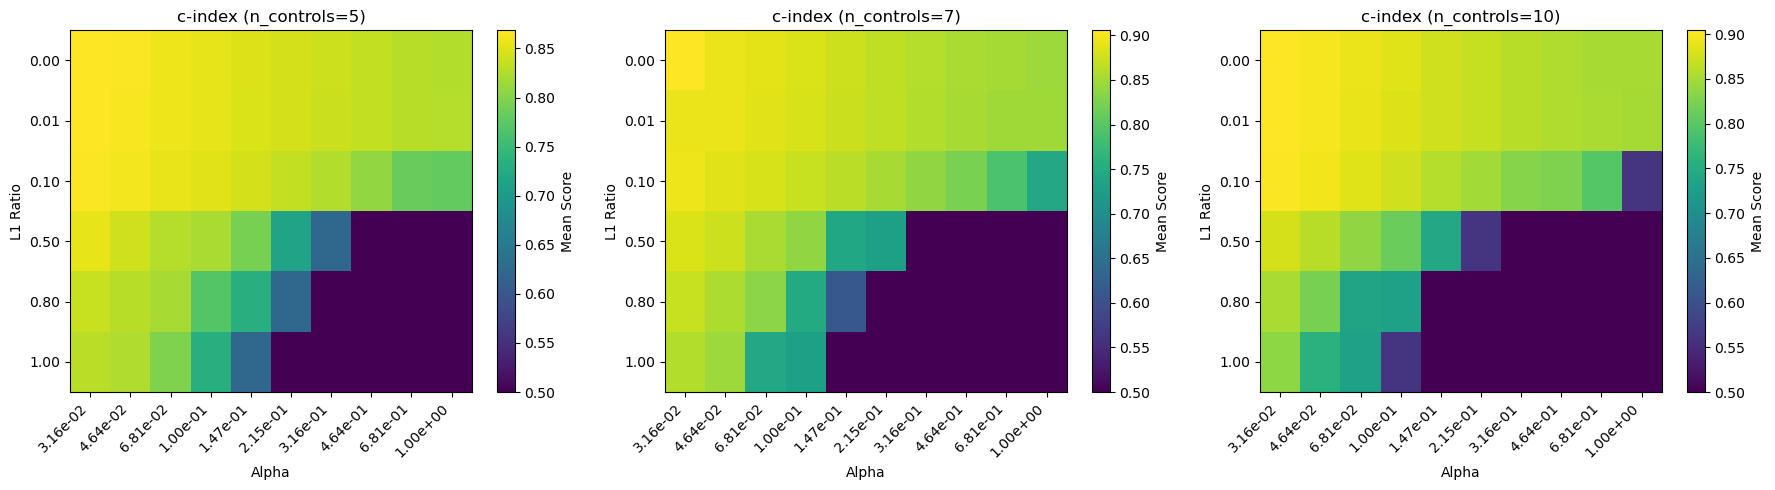

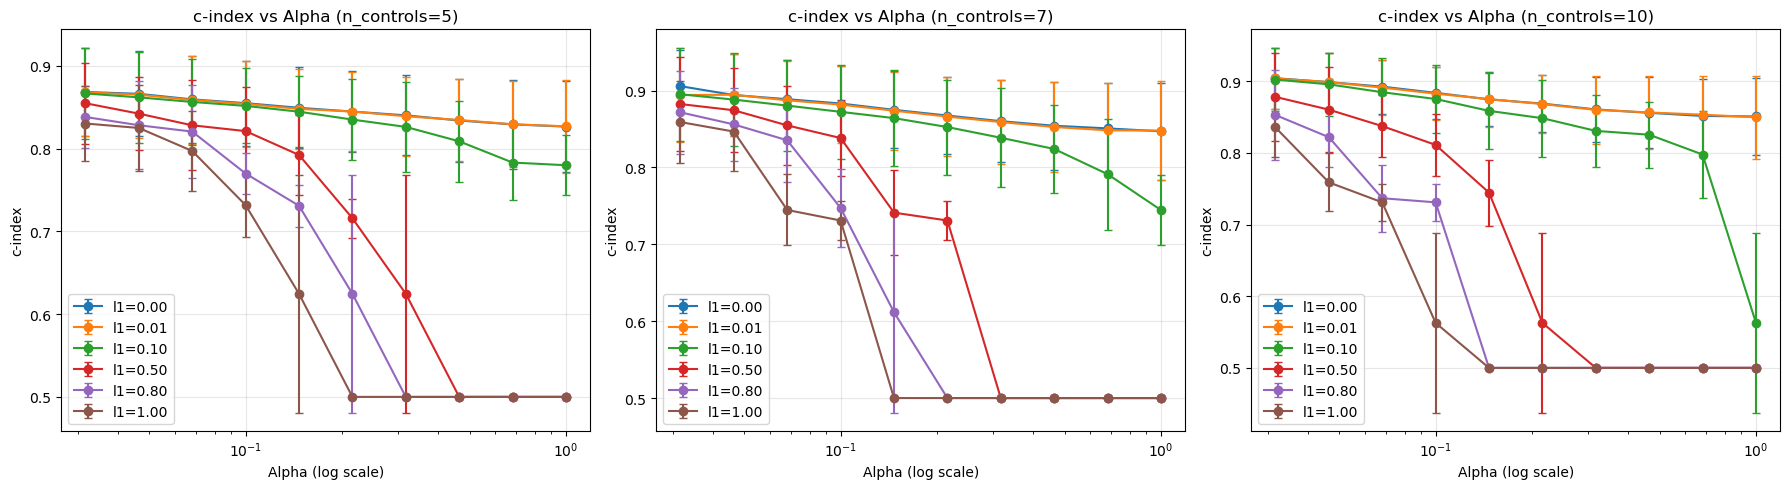

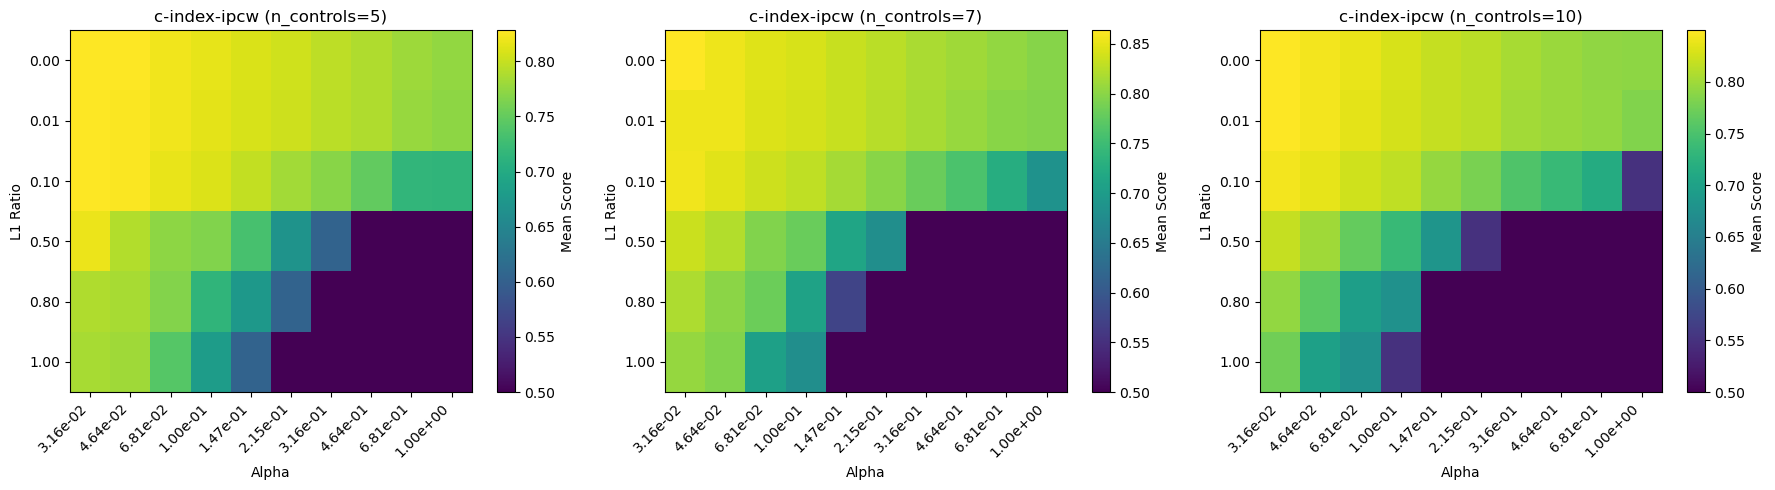

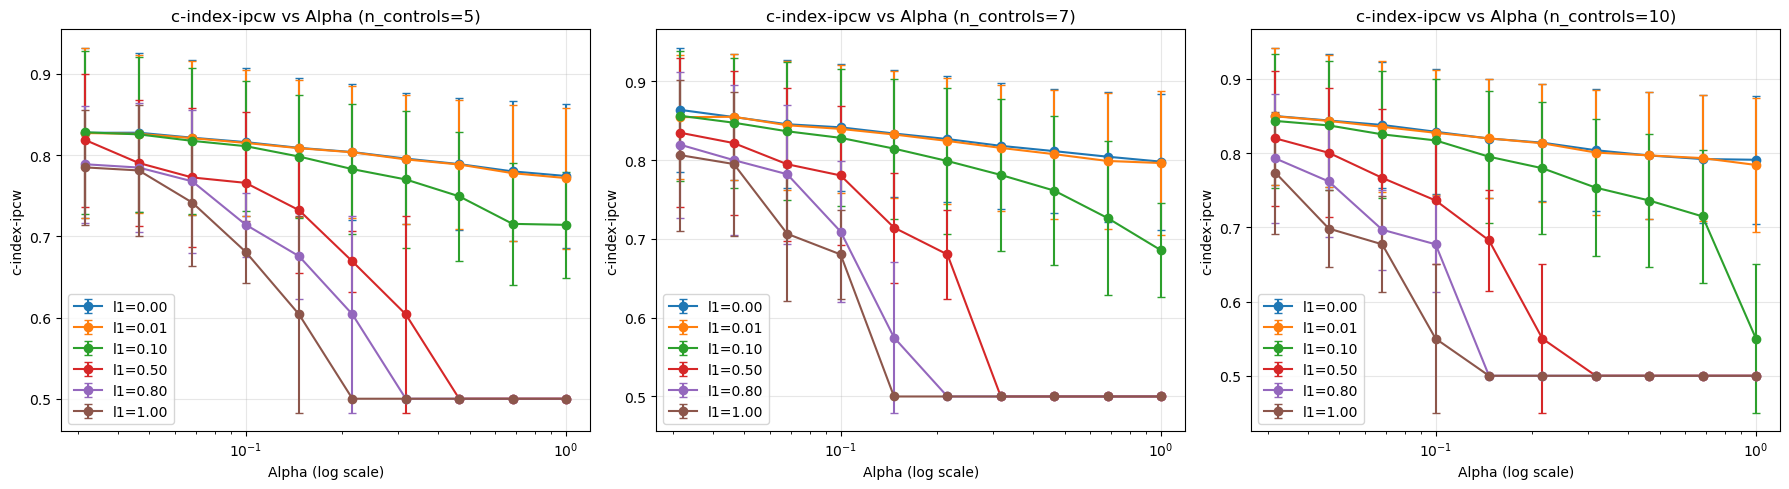

In [23]:

# Access best parameters
print(best_params['c-index-ipcw'])

# Visualize results
plot_grid_search_results(summary_df, metric='c-index')
plot_grid_search_results(summary_df, metric='c-index-ipcw')

In [ ]:
# Train and evaluate model using best c-index-ipcw hyperparameters on full train/test split
# IMPORTANT: Using same subsampling approach as in CV to maintain consistency
print("="*80)
print("FINAL MODEL EVALUATION WITH BEST C-INDEX-IPCW HYPERPARAMETERS")
print("="*80)

if 'c-index-ipcw' in best_params:
    # Get best hyperparameters
    best_ipcw_params = best_params['c-index-ipcw']
    n_controls_best = best_ipcw_params['n_controls']
    l1_ratio_best = best_ipcw_params['l1_ratio']
    alpha_best = best_ipcw_params['alpha']
    
    print(f"\nBest c-index-ipcw hyperparameters:")
    print(f"  n_controls_per_case: {n_controls_best}")
    print(f"  l1_ratio: {l1_ratio_best:.4f}")
    print(f"  alpha: {alpha_best:.4e}")
    print(f"  CV Mean: {best_ipcw_params['mean']:.4f}")
    print(f"  CV Std:  {best_ipcw_params['std']:.4f}")
    
    print(f"\n" + "-"*80)
    print("TRAINING ON FULL TRAINING SET WITH SUBSAMPLING")
    print("-"*80)
    print("(Maintaining consistency with CV approach)")
    
    # Apply subsampling to full training set (same as in CV)
    X_train_sub_final, y_train_sub_final, sub_dataset_final = sample_case_control(
        subsampling, 
        event_col='Regional LN recurrence', 
        time_col='Survival days', 
        n_controls_per_case=n_controls_best, 
        feature_columns=feature_columns,
        random_state=12
    )
    
    print(f"\nTraining data after subsampling:")
    print(f"  Original training samples: {len(x_train)}")
    print(f"  Subsampled training samples: {len(X_train_sub_final)}")
    print(f"  Events in subsampled data: {y_train_sub_final['event'].sum()}")
    print(f"  Censored in subsampled data: {(~y_train_sub_final['event']).sum()}")
    print(f"  Test samples: {len(x_test)}")
    print(f"  Events in test data: {y_test['event'].sum()}")
    
    # Apply scaling
    scaler_final = StandardScaler()
    X_train_sub_scaled_final = scaler_final.fit_transform(X_train_sub_final)
    X_test_scaled_final = scaler_final.transform(x_test)
    
    print(f"\nTraining model with Cox regression...")
    
    # Train the model on subsampled training data
    model_final = CoxnetSurvivalAnalysis(
        alphas=[alpha_best], 
        l1_ratio=l1_ratio_best, 
        fit_baseline_model=True,
        max_iter=200000
    )
    model_final.fit(X_train_sub_scaled_final, y_train_sub_final)
    
    print(f"Model trained successfully!")
    print(f"Number of selected features: {np.sum(model_final.coef_.flatten() != 0)}")
    
    print(f"\n" + "-"*80)
    print("TEST SET EVALUATION")
    print("-"*80)
    
    # Predict on test set
    predicted_risk_final = model_final.predict(X_test_scaled_final)
    
    # Calculate all metrics
    # 1. C-Index
    test_cindex_final = concordance_index_censored(
        y_test['event'], 
        y_test['time'], 
        predicted_risk_final
    )[0]
    
    # 2. C-Index IPCW
    max_time_final = min(y_train_sub_final['time'].max(), y_test['time'].max()) * 0.9
    test_cindex_ipcw_final = concordance_index_ipcw(
        y_train_sub_final, 
        y_test, 
        predicted_risk_final, 
        tau=max_time_final
    )[0]
    
    # 3. Integrated Brier Score
    surv_funcs_final = model_final.predict_survival_function(X_test_scaled_final)
    times_brier = np.array([2*365, 5*365, 10*365])
    times_brier = times_brier[times_brier <= max_time_final]
    
    if len(times_brier) > 0:
        predicted_survival_probs_final = np.asarray(
            [[fn(t) for t in times_brier] for fn in surv_funcs_final]
        )
        test_brier_final = integrated_brier_score(
            y_train_sub_final, 
            y_test, 
            predicted_survival_probs_final, 
            times_brier
        )
    else:
        test_brier_final = np.nan
    
    # 4. Individual Brier scores at specific time points
    brier_2yr = np.nan
    brier_5yr = np.nan
    brier_10yr = np.nan
    
    if 2*365 in times_brier:
        idx_2yr = np.where(times_brier == 2*365)[0][0]
        from sksurv.metrics import brier_score
        brier_2yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_2yr], times_brier[idx_2yr])[1][0]
    
    if 5*365 in times_brier:
        idx_5yr = np.where(times_brier == 5*365)[0][0]
        brier_5yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_5yr], times_brier[idx_5yr])[1][0]
    
    if 10*365 in times_brier:
        idx_10yr = np.where(times_brier == 10*365)[0][0]
        brier_10yr = brier_score(y_train_sub_final, y_test, predicted_survival_probs_final[:, idx_10yr], times_brier[idx_10yr])[1][0]
    
    print(f"\nTest Set Performance Metrics:")
    print(f"  C-Index:                    {test_cindex_final:.4f}")
    print(f"  C-Index IPCW:               {test_cindex_ipcw_final:.4f}")
    print(f"  Integrated Brier Score:     {test_brier_final:.4f}")
    print(f"  Brier Score @ 2 years:      {brier_2yr:.4f}" if not np.isnan(brier_2yr) else "  Brier Score @ 2 years:      N/A")
    print(f"  Brier Score @ 5 years:      {brier_5yr:.4f}" if not np.isnan(brier_5yr) else "  Brier Score @ 5 years:      N/A")
    print(f"  Brier Score @ 10 years:     {brier_10yr:.4f}" if not np.isnan(brier_10yr) else "  Brier Score @ 10 years:     N/A")
    
    print(f"\n" + "-"*80)
    print("COMPARISON: CV vs TEST PERFORMANCE")
    print("-"*80)
    
    print(f"\nC-Index IPCW (optimized metric):")
    print(f"  CV Performance:   {best_ipcw_params['mean']:.4f} ± {best_ipcw_params['std']:.4f}")
    print(f"  Test Performance: {test_cindex_ipcw_final:.4f}")
    print(f"  Difference:       {test_cindex_ipcw_final - best_ipcw_params['mean']:+.4f}")
    
    # Get CV performance for c-index (not the optimized metric)
    n_c = n_controls_best
    l1_r = l1_ratio_best
    a = alpha_best
    cv_cindex = results[n_c][l1_r][a].loc['Mean', 'c-index']
    cv_cindex_std = results[n_c][l1_r][a].loc['Std', 'c-index']
    
    print(f"\nC-Index (not optimized):")
    print(f"  CV Performance:   {cv_cindex:.4f} ± {cv_cindex_std:.4f}")
    print(f"  Test Performance: {test_cindex_final:.4f}")
    print(f"  Difference:       {test_cindex_final - cv_cindex:+.4f}")
    
    
    # Store results for later use
    final_model_results = {
        'model': model_final,
        'scaler': scaler_final,
        'hyperparameters': {
            'n_controls': n_controls_best,
            'l1_ratio': l1_ratio_best,
            'alpha': alpha_best
        },
        'test_metrics': {
            'c-index': test_cindex_final,
            'c-index-ipcw': test_cindex_ipcw_final,
            'int-brier-score': test_brier_final,
            'brier_2yr': brier_2yr,
            'brier_5yr': brier_5yr,
            'brier_10yr': brier_10yr
        }
        #'selected_features': selected_features_df,
        #'n_features': len(selected_features_df)
    }
    
    print(f"\n✅ Results stored in 'final_model_results' variable")
    
else:
    print("\n⚠️  No valid c-index-ipcw configuration found!")

print("\n" + "="*80)

FINAL MODEL EVALUATION WITH BEST C-INDEX-IPCW HYPERPARAMETERS

Best c-index-ipcw hyperparameters:
  n_controls_per_case: 10
  l1_ratio: 0.1000
  alpha: 1.1659e-02
  CV Mean: 0.8565
  CV Std:  0.0996

--------------------------------------------------------------------------------
TRAINING ON FULL TRAINING SET WITH SUBSAMPLING
--------------------------------------------------------------------------------
(Maintaining consistency with CV approach)

Training data after subsampling:
  Original training samples: 2376
  Subsampled training samples: 291
  Events in subsampled data: 27
  Censored in subsampled data: 264
  Test samples: 594
  Events in test data: 6

Training model with Cox regression...
Model trained successfully!
Number of selected features: 55

--------------------------------------------------------------------------------
TEST SET EVALUATION
--------------------------------------------------------------------------------

Test Set Performance Metrics:
  C-Index:          

In [57]:
# Fine-tune the number of controls per case with multiple alpha values
print("=== OPTIMIZING NUMBER OF CONTROLS PER CASE (WITH MULTIPLE ALPHAS) ===")

# Test different numbers of controls per case
controls_per_case_options = [1, 3, 4, 5, 7, 10, 15]
# Define alpha range for testing
alpha_range = np.logspace(-2, -1, 10)  # 10 alpha values to test
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

# Store results: controls_results[n_controls][alpha] = results_df
controls_results = {}

for n_controls in controls_per_case_options:
    print(f"\n{'='*70}")
    print(f"Testing {n_controls} controls per case with {len(alpha_range)} alpha values...")
    print(f"{'='*70}")
    
    controls_results[n_controls] = {}
    
    for alpha in alpha_range:
        print(f"  Alpha: {alpha:.6f}", end=" ")
        
        results_df = subsampling_cross_validation(
            subsampling, x_train, y_train, sgkf_1, alpha=alpha, l1_ratio=l1_ratio, 
            metrics=metrics, n_controls_per_case=n_controls, feature_columns=feature_columns
        )
        controls_results[n_controls][alpha] = results_df
        
        # Print inline summary
        print(f"→ C-Idx: {results_df.loc['Mean', 'c-index']:.4f}, IPCW: {results_df.loc['Mean', 'c-index-ipcw']:.4f}, Brier: {results_df.loc['Mean', 'int-brier-score']:.4f}")
    
    # Find and display best 3 alphas for this n_controls
    print(f"\n  Best 3 alphas for {n_controls} controls per case:")
    
    # Best for C-Index
    cindex_scores = [(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index']) for alpha in alpha_range]
    cindex_scores.sort(key=lambda x: x[1], reverse=True)
    print(f"    C-Index: α={cindex_scores[0][0]:.6f} ({cindex_scores[0][1]:.4f}), "
          f"α={cindex_scores[1][0]:.6f} ({cindex_scores[1][1]:.4f}), "
          f"α={cindex_scores[2][0]:.6f} ({cindex_scores[2][1]:.4f})")
    
    # Best for IPCW C-Index
    ipcw_scores = [(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index-ipcw']) for alpha in alpha_range]
    ipcw_scores.sort(key=lambda x: x[1], reverse=True)
    print(f"    IPCW C-Index: α={ipcw_scores[0][0]:.6f} ({ipcw_scores[0][1]:.4f}), "
          f"α={ipcw_scores[1][0]:.6f} ({ipcw_scores[1][1]:.4f}), "
          f"α={ipcw_scores[2][0]:.6f} ({ipcw_scores[2][1]:.4f})")
    
    # Best for Brier Score (lower is better)
    brier_scores = [(alpha, controls_results[n_controls][alpha].loc['Mean', 'int-brier-score']) for alpha in alpha_range]
    brier_scores.sort(key=lambda x: x[1])
    print(f"    Brier Score: α={brier_scores[0][0]:.6f} ({brier_scores[0][1]:.4f}), "
          f"α={brier_scores[1][0]:.6f} ({brier_scores[1][1]:.4f}), "
          f"α={brier_scores[2][0]:.6f} ({brier_scores[2][1]:.4f})")

print("\n" + "="*70)
print("Controls per case optimization with multiple alphas completed!")
print("="*70)

=== OPTIMIZING NUMBER OF CONTROLS PER CASE (WITH MULTIPLE ALPHAS) ===

Testing 1 controls per case with 10 alpha values...
  Alpha: 0.010000 

c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: ConvergenceWarning: Optimization terminated early, you might want to increase the number of iterations (max_iter=100000).
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:86: RuntimeWarning: divide by zero encountered in divide
  y = np.cumsum(n_events / divisor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


→ C-Idx: 0.7305, IPCW: 0.6604, Brier: 0.2211
  Alpha: 0.012915 → C-Idx: 0.7526, IPCW: 0.6708, Brier: 0.0954
  Alpha: 0.016681 → C-Idx: 0.7526, IPCW: 0.6708, Brier: 0.0954
  Alpha: 0.016681 → C-Idx: 0.7708, IPCW: 0.6857, Brier: 0.0863
  Alpha: 0.021544 → C-Idx: 0.7708, IPCW: 0.6857, Brier: 0.0863
  Alpha: 0.021544 → C-Idx: 0.7965, IPCW: 0.7021, Brier: 0.0782
  Alpha: 0.027826 → C-Idx: 0.7965, IPCW: 0.7021, Brier: 0.0782
  Alpha: 0.027826 → C-Idx: 0.8214, IPCW: 0.7225, Brier: 0.0710
  Alpha: 0.035938 → C-Idx: 0.8214, IPCW: 0.7225, Brier: 0.0710
  Alpha: 0.035938 → C-Idx: 0.8209, IPCW: 0.7237, Brier: 0.0686
  Alpha: 0.046416 → C-Idx: 0.8209, IPCW: 0.7237, Brier: 0.0686
  Alpha: 0.046416 → C-Idx: 0.8174, IPCW: 0.7153, Brier: 0.0686
  Alpha: 0.059948 → C-Idx: 0.8174, IPCW: 0.7153, Brier: 0.0686
  Alpha: 0.059948 → C-Idx: 0.7969, IPCW: 0.6884, Brier: 0.0683
  Alpha: 0.077426 → C-Idx: 0.7969, IPCW: 0.6884, Brier: 0.0683
  Alpha: 0.077426 → C-Idx: 0.7620, IPCW: 0.6514, Brier: 0.0671
  Alpha: 0

In [58]:
# Create summaries for controls per case optimization (with best alpha for each)
print("=== CONTROLS PER CASE OPTIMIZATION RESULTS ===")
print("(Showing best performance across all tested alphas)\n")

controls_cindex_summary = []
controls_ipcw_summary = []
controls_brier_summary = []

# Store best alpha information for each n_controls and metric
best_configs = {}

for n_controls in controls_per_case_options:
    best_configs[n_controls] = {}
    
    # Find best alpha for each metric
    best_cindex = max([(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index']) 
                       for alpha in controls_results[n_controls].keys()], key=lambda x: x[1])
    best_ipcw = max([(alpha, controls_results[n_controls][alpha].loc['Mean', 'c-index-ipcw']) 
                     for alpha in controls_results[n_controls].keys()], key=lambda x: x[1])
    best_brier = min([(alpha, controls_results[n_controls][alpha].loc['Mean', 'int-brier-score']) 
                      for alpha in controls_results[n_controls].keys()], key=lambda x: x[1])
    
    best_configs[n_controls]['c-index'] = {'alpha': best_cindex[0], 'score': best_cindex[1]}
    best_configs[n_controls]['c-index-ipcw'] = {'alpha': best_ipcw[0], 'score': best_ipcw[1]}
    best_configs[n_controls]['int-brier-score'] = {'alpha': best_brier[0], 'score': best_brier[1]}
    
    # Get std from the best alpha results
    controls_cindex_summary.append({
        'N_Controls': n_controls,
        'Best_Alpha': best_cindex[0],
        'Mean': best_cindex[1],
        'Std': controls_results[n_controls][best_cindex[0]].loc['Std', 'c-index']
    })
    controls_ipcw_summary.append({
        'N_Controls': n_controls,
        'Best_Alpha': best_ipcw[0],
        'Mean': best_ipcw[1],
        'Std': controls_results[n_controls][best_ipcw[0]].loc['Std', 'c-index-ipcw']
    })
    controls_brier_summary.append({
        'N_Controls': n_controls,
        'Best_Alpha': best_brier[0],
        'Mean': best_brier[1],
        'Std': controls_results[n_controls][best_brier[0]].loc['Std', 'int-brier-score']
    })

controls_cindex_df = pd.DataFrame(controls_cindex_summary)
controls_ipcw_df = pd.DataFrame(controls_ipcw_summary)
controls_brier_df = pd.DataFrame(controls_brier_summary)

print("C-Index Results (with best alpha for each):")
print(controls_cindex_df.sort_values('Mean', ascending=False).to_string(index=False))
print(f"Best overall: {controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax(), 'N_Controls']} controls per case "
      f"(α={controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax(), 'Best_Alpha']:.6f})")

print("\nIPCW C-Index Results (with best alpha for each):")
print(controls_ipcw_df.sort_values('Mean', ascending=False).to_string(index=False))
print(f"Best overall: {controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax(), 'N_Controls']} controls per case "
      f"(α={controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax(), 'Best_Alpha']:.6f})")

print("\nBrier Score Results (lower is better, with best alpha for each):")
print(controls_brier_df.sort_values('Mean', ascending=True).to_string(index=False))
print(f"Best overall: {controls_brier_df.loc[controls_brier_df['Mean'].idxmin(), 'N_Controls']} controls per case "
      f"(α={controls_brier_df.loc[controls_brier_df['Mean'].idxmin(), 'Best_Alpha']:.6f})")

=== CONTROLS PER CASE OPTIMIZATION RESULTS ===
(Showing best performance across all tested alphas)

C-Index Results (with best alpha for each):
 N_Controls  Best_Alpha     Mean      Std
          1    0.027826 0.821392 0.094979
          7    0.010000 0.815246 0.057891
         15    0.010000 0.798571 0.072993
         10    0.012915 0.797262 0.058396
          3    0.010000 0.786037 0.125416
          5    0.012915 0.780981 0.146727
          4    0.016681 0.769044 0.091744
Best overall: 1 controls per case (α=0.027826)

IPCW C-Index Results (with best alpha for each):
 N_Controls  Best_Alpha     Mean      Std
          1    0.035938 0.723726 0.138330
          5    0.046416 0.716696 0.060044
          7    0.012915 0.715373 0.094781
         10    0.010000 0.706645 0.095733
          3    0.010000 0.703692 0.149899
         15    0.016681 0.699208 0.082886
          4    0.027826 0.670754 0.129547
Best overall: 1 controls per case (α=0.035938)

Brier Score Results (lower is better, w

In [59]:
# Display top 3 alpha configurations for each case-control option
print("=== TOP 3 ALPHA CONFIGURATIONS FOR EACH CASE-CONTROL OPTION ===\n")

for n_controls in controls_per_case_options:
    print(f"{'='*70}")
    print(f"N_CONTROLS = {n_controls}")
    print(f"{'='*70}")
    
    # Get all alpha results for this n_controls
    alpha_results = controls_results[n_controls]
    
    # C-Index Top 3
    print(f"\n  📊 C-INDEX (Top 3):")
    cindex_ranked = sorted([(alpha, df.loc['Mean', 'c-index'], df.loc['Std', 'c-index']) 
                           for alpha, df in alpha_results.items()], 
                          key=lambda x: x[1], reverse=True)[:3]
    for rank, (alpha, mean, std) in enumerate(cindex_ranked, 1):
        print(f"    {rank}. α = {alpha:.6f} → {mean:.4f} ± {std:.4f}")
    
    # IPCW C-Index Top 3
    print(f"\n  📊 IPCW C-INDEX (Top 3):")
    ipcw_ranked = sorted([(alpha, df.loc['Mean', 'c-index-ipcw'], df.loc['Std', 'c-index-ipcw']) 
                         for alpha, df in alpha_results.items()], 
                        key=lambda x: x[1], reverse=True)[:3]
    for rank, (alpha, mean, std) in enumerate(ipcw_ranked, 1):
        print(f"    {rank}. α = {alpha:.6f} → {mean:.4f} ± {std:.4f}")
    
    # Brier Score Top 3 (lower is better)
    print(f"\n  📊 BRIER SCORE (Top 3 - lower is better):")
    brier_ranked = sorted([(alpha, df.loc['Mean', 'int-brier-score'], df.loc['Std', 'int-brier-score']) 
                          for alpha, df in alpha_results.items()], 
                         key=lambda x: x[1])[:3]
    for rank, (alpha, mean, std) in enumerate(brier_ranked, 1):
        print(f"    {rank}. α = {alpha:.6f} → {mean:.4f} ± {std:.4f}")
    
    print()

print("="*70)

=== TOP 3 ALPHA CONFIGURATIONS FOR EACH CASE-CONTROL OPTION ===

N_CONTROLS = 1

  📊 C-INDEX (Top 3):
    1. α = 0.027826 → 0.8214 ± 0.0950
    2. α = 0.035938 → 0.8209 ± 0.0995
    3. α = 0.046416 → 0.8174 ± 0.1059

  📊 IPCW C-INDEX (Top 3):
    1. α = 0.035938 → 0.7237 ± 0.1383
    2. α = 0.027826 → 0.7225 ± 0.1674
    3. α = 0.046416 → 0.7153 ± 0.1367

  📊 BRIER SCORE (Top 3 - lower is better):
    1. α = 0.100000 → 0.0671 ± 0.0201
    2. α = 0.077426 → 0.0671 ± 0.0193
    3. α = 0.059948 → 0.0683 ± 0.0200

N_CONTROLS = 3

  📊 C-INDEX (Top 3):
    1. α = 0.010000 → 0.7860 ± 0.1254
    2. α = 0.016681 → 0.7819 ± 0.1046
    3. α = 0.012915 → 0.7810 ± 0.1150

  📊 IPCW C-INDEX (Top 3):
    1. α = 0.010000 → 0.7037 ± 0.1499
    2. α = 0.016681 → 0.6925 ± 0.1189
    3. α = 0.046416 → 0.6906 ± 0.0519

  📊 BRIER SCORE (Top 3 - lower is better):
    1. α = 0.046416 → 0.0334 ± 0.0154
    2. α = 0.100000 → 0.0336 ± 0.0184
    3. α = 0.077426 → 0.0337 ± 0.0186

N_CONTROLS = 4

  📊 C-INDEX (Top 

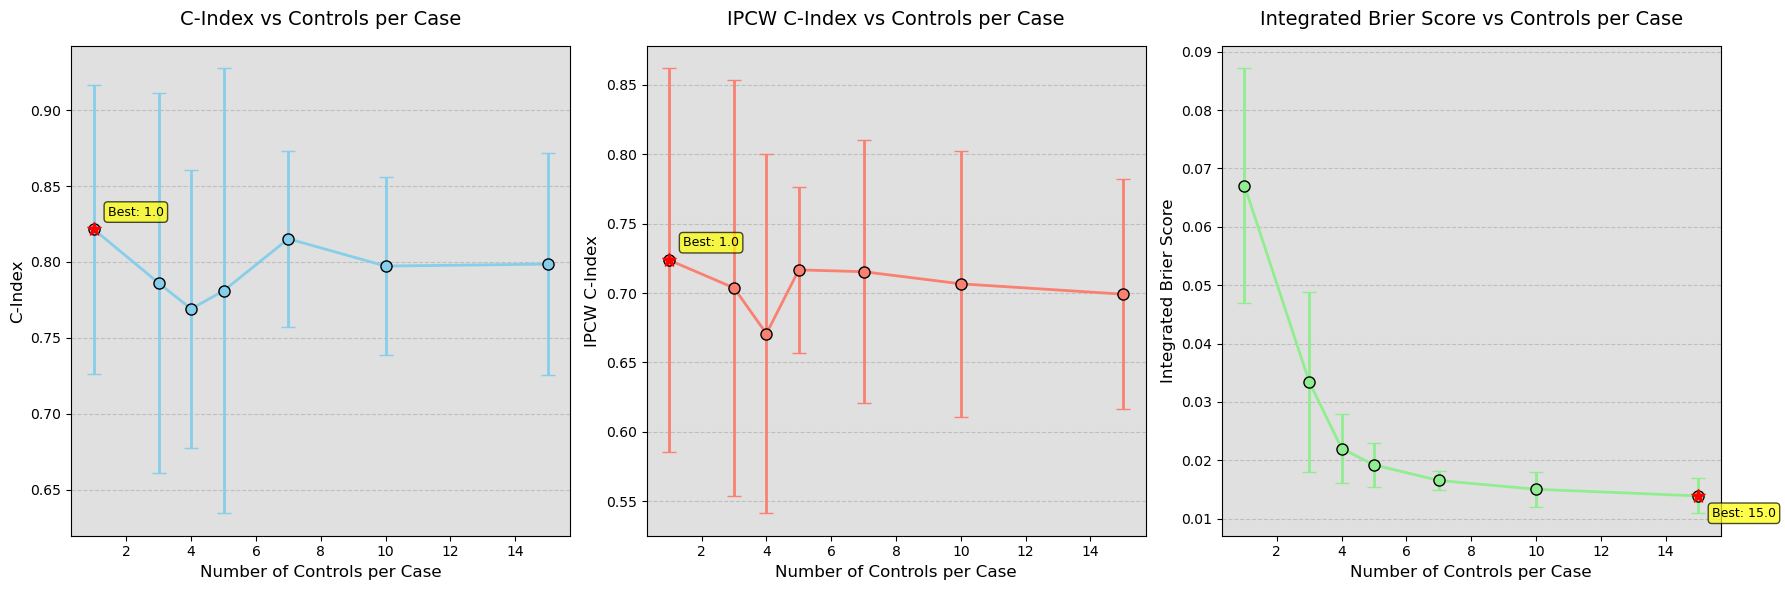

In [60]:
# Plot controls per case optimization results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor('None')

# C-Index plot
axes[0].set_facecolor('#e0e0e0')
axes[0].errorbar(controls_cindex_df['N_Controls'], controls_cindex_df['Mean'], 
                yerr=controls_cindex_df['Std'], fmt='o-', capsize=5, color='skyblue', 
                markeredgecolor='black', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Controls per Case', fontsize=12)
axes[0].set_ylabel('C-Index', fontsize=12)
axes[0].set_title('C-Index vs Controls per Case', fontsize=14, pad=15)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Mark best point
best_controls_cindex = controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax()]
axes[0].scatter(best_controls_cindex['N_Controls'], best_controls_cindex['Mean'], 
               color='red', s=100, zorder=5, marker='*')
axes[0].annotate(f'Best: {best_controls_cindex["N_Controls"]}', 
                xy=(best_controls_cindex['N_Controls'], best_controls_cindex['Mean']),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9)

# IPCW C-Index plot
axes[1].set_facecolor('#e0e0e0')
axes[1].errorbar(controls_ipcw_df['N_Controls'], controls_ipcw_df['Mean'], 
                yerr=controls_ipcw_df['Std'], fmt='o-', capsize=5, color='salmon',
                markeredgecolor='black', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Controls per Case', fontsize=12)
axes[1].set_ylabel('IPCW C-Index', fontsize=12)
axes[1].set_title('IPCW C-Index vs Controls per Case', fontsize=14, pad=15)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Mark best point
best_controls_ipcw = controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax()]
axes[1].scatter(best_controls_ipcw['N_Controls'], best_controls_ipcw['Mean'], 
               color='red', s=100, zorder=5, marker='*')
axes[1].annotate(f'Best: {best_controls_ipcw["N_Controls"]}', 
                xy=(best_controls_ipcw['N_Controls'], best_controls_ipcw['Mean']),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9)

# Brier Score plot
axes[2].set_facecolor('#e0e0e0')
axes[2].errorbar(controls_brier_df['N_Controls'], controls_brier_df['Mean'], 
                yerr=controls_brier_df['Std'], fmt='o-', capsize=5, color='lightgreen',
                markeredgecolor='black', linewidth=2, markersize=8)
axes[2].set_xlabel('Number of Controls per Case', fontsize=12)
axes[2].set_ylabel('Integrated Brier Score', fontsize=12)
axes[2].set_title('Integrated Brier Score vs Controls per Case', fontsize=14, pad=15)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

# Mark best point (minimum for Brier score)
best_controls_brier = controls_brier_df.loc[controls_brier_df['Mean'].idxmin()]
axes[2].scatter(best_controls_brier['N_Controls'], best_controls_brier['Mean'], 
               color='red', s=100, zorder=5, marker='*')
axes[2].annotate(f'Best: {best_controls_brier["N_Controls"]}', 
                xy=(best_controls_brier['N_Controls'], best_controls_brier['Mean']),
                xytext=(10, -15), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9)

plt.tight_layout()
plt.show()

In [35]:
# Analyze the trade-offs and select optimal number of controls
print("=== TRADE-OFF ANALYSIS ===")

# Get the best values for each metric
best_n_cindex = controls_cindex_df.loc[controls_cindex_df['Mean'].idxmax(), 'N_Controls']
best_n_ipcw = controls_ipcw_df.loc[controls_ipcw_df['Mean'].idxmax(), 'N_Controls']
best_n_brier = controls_brier_df.loc[controls_brier_df['Mean'].idxmin(), 'N_Controls']

print(f"Best for C-Index: {best_n_cindex} controls per case")
print(f"Best for IPCW C-Index: {best_n_ipcw} controls per case")
print(f"Best for Brier Score: {best_n_brier} controls per case")

# Calculate sample sizes for each option
print("\n=== SAMPLE SIZE ANALYSIS ===")
n_events = subsampling['Regional LN recurrence'].sum()
print(f"Number of events (cases): {n_events}")

for n_controls in controls_per_case_options:
    total_samples = n_events * (1 + n_controls)  # events + controls
    print(f"{n_controls} controls per case → ~{total_samples} total samples")

# Check if there's a consensus or recommend based on multiple criteria
from collections import Counter
best_choices = [best_n_cindex, best_n_ipcw, best_n_brier]
consensus = Counter(best_choices).most_common(1)[0]

print(f"\n=== RECOMMENDATION ===")
if consensus[1] > 1:
    print(f"Consensus choice: {consensus[0]} controls per case (best for {consensus[1]} out of 3 metrics)")
    optimal_n_controls = consensus[0]
else:
    # If no consensus, look for a balanced choice
    # Calculate normalized scores (0-1) for each metric and find the best overall
    scores_matrix = []
    for n_controls in controls_per_case_options:
        cindex_score = controls_cindex_df[controls_cindex_df['N_Controls'] == n_controls]['Mean'].iloc[0]
        ipcw_score = controls_ipcw_df[controls_ipcw_df['N_Controls'] == n_controls]['Mean'].iloc[0]
        brier_score = controls_brier_df[controls_brier_df['N_Controls'] == n_controls]['Mean'].iloc[0]
        
        # Normalize scores (higher is better for C-indices, lower is better for Brier)
        norm_cindex = (cindex_score - controls_cindex_df['Mean'].min()) / (controls_cindex_df['Mean'].max() - controls_cindex_df['Mean'].min())
        norm_ipcw = (ipcw_score - controls_ipcw_df['Mean'].min()) / (controls_ipcw_df['Mean'].max() - controls_ipcw_df['Mean'].min())
        norm_brier = (controls_brier_df['Mean'].max() - brier_score) / (controls_brier_df['Mean'].max() - controls_brier_df['Mean'].min())
        
        avg_score = (norm_cindex + norm_ipcw + norm_brier) / 3
        scores_matrix.append({'N_Controls': n_controls, 'Avg_Normalized_Score': avg_score})
    
    scores_df = pd.DataFrame(scores_matrix)
    optimal_n_controls = scores_df.loc[scores_df['Avg_Normalized_Score'].idxmax(), 'N_Controls']
    print(f"Balanced choice based on all metrics: {optimal_n_controls} controls per case")
    
print(f"\nRecommended n_controls_per_case: {optimal_n_controls}")

# Update the variable for future use
n_controls_per_case = int(optimal_n_controls)
print(f"Updated n_controls_per_case = {n_controls_per_case}")

=== TRADE-OFF ANALYSIS ===
Best for C-Index: 1 controls per case
Best for IPCW C-Index: 1 controls per case
Best for Brier Score: 15 controls per case

=== SAMPLE SIZE ANALYSIS ===
Number of events (cases): 27.0
1 controls per case → ~54.0 total samples
3 controls per case → ~108.0 total samples
4 controls per case → ~135.0 total samples
5 controls per case → ~162.0 total samples
7 controls per case → ~216.0 total samples
10 controls per case → ~297.0 total samples
15 controls per case → ~432.0 total samples

=== RECOMMENDATION ===
Consensus choice: 1 controls per case (best for 2 out of 3 metrics)

Recommended n_controls_per_case: 1
Updated n_controls_per_case = 1


In [ ]:
#best controls per case
n_controls_per_case = 10

In [37]:
# Test multiple alpha values to find the best one
results_all_alphas = {}
metrics = ['c-index', 'c-index-ipcw', 'int-brier-score']

for alpha in list_alphas:
    print(f"Testing alpha: {alpha:.4f}")
    results_df = subsampling_cross_validation(
        subsampling, x_train, y_train, sgkf_1, alpha=alpha, l1_ratio=l1_ratio, 
        metrics=metrics, n_controls_per_case=n_controls_per_case, feature_columns=feature_columns
    )
    results_all_alphas[alpha] = results_df

print("Alpha testing completed!")

Testing alpha: 0.0003


c:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis\functions\subsampling.py:134: ConvergenceWarning: Optimization terminated early, you might want to increase the number of iterations (max_iter=100000).
  model.fit(X_train_sub_scaled, y_train_sub)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:69: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:80: RuntimeWarning: invalid value encountered in scalar subtract
  value -= risk_score[k : (k + d)].sum()
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


ValueError: Input estimate contains NaN.

In [ ]:
# Get summaries for each metric
cindex_summary = create_alpha_summary(results_all_alphas, 'c-index')
ipcw_summary = create_alpha_summary(results_all_alphas, 'c-index-ipcw')
brier_summary = create_alpha_summary(results_all_alphas, 'int-brier-score')

print("C-Index Results:")
print(cindex_summary.sort_values('Mean', ascending=False).head())
print("\nIPCW C-Index Results:")
print(ipcw_summary.sort_values('Mean', ascending=False).head())
print("\nBrier Score Results (lower is better):")
print(brier_summary.sort_values('Mean', ascending=True).head())

C-Index Results:
       Alpha      Mean       Std
12  0.042813  0.781130  0.074455
2   0.012743  0.780557  0.146782
1   0.011288  0.779824  0.138688
11  0.037927  0.779232  0.074364
3   0.014384  0.778032  0.145089

IPCW C-Index Results:
       Alpha      Mean       Std
12  0.042813  0.726221  0.049015
1   0.011288  0.714983  0.148794
13  0.048329  0.714481  0.070984
0   0.010000  0.714112  0.147604
2   0.012743  0.711271  0.151113

Brier Score Results (lower is better):
       Alpha      Mean       Std
13  0.048329  0.019225  0.003678
19  0.100000  0.019235  0.003487
12  0.042813  0.019238  0.003783
18  0.088587  0.019258  0.003503
17  0.078476  0.019279  0.003517


In [ ]:
# Find the best alpha for each metric
print("=== BEST ALPHAS FOR EACH METRIC ===")

# Best alpha for C-Index (higher is better)
best_alpha_cindex = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)

# Best alpha for IPCW C-Index (higher is better)
best_alpha_ipcw = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)

# Best alpha for Brier Score (lower is better)
best_alpha_brier = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

print(f"\nSummary:")
print(f"Best alpha for C-Index: {best_alpha_cindex:.4f}")
print(f"Best alpha for IPCW C-Index: {best_alpha_ipcw:.4f}")
print(f"Best alpha for Brier Score: {best_alpha_brier:.4f}")

=== BEST ALPHAS FOR EACH METRIC ===
Best alpha for C-Index: 0.0428
Score: 0.7811 ± 0.0745
Best alpha for IPCW C-Index: 0.0428
Score: 0.7262 ± 0.0490
Best alpha for Brier Score: 0.0483
Score: 0.0192 ± 0.0037

Summary:
Best alpha for C-Index: 0.0428
Best alpha for IPCW C-Index: 0.0428
Best alpha for Brier Score: 0.0483


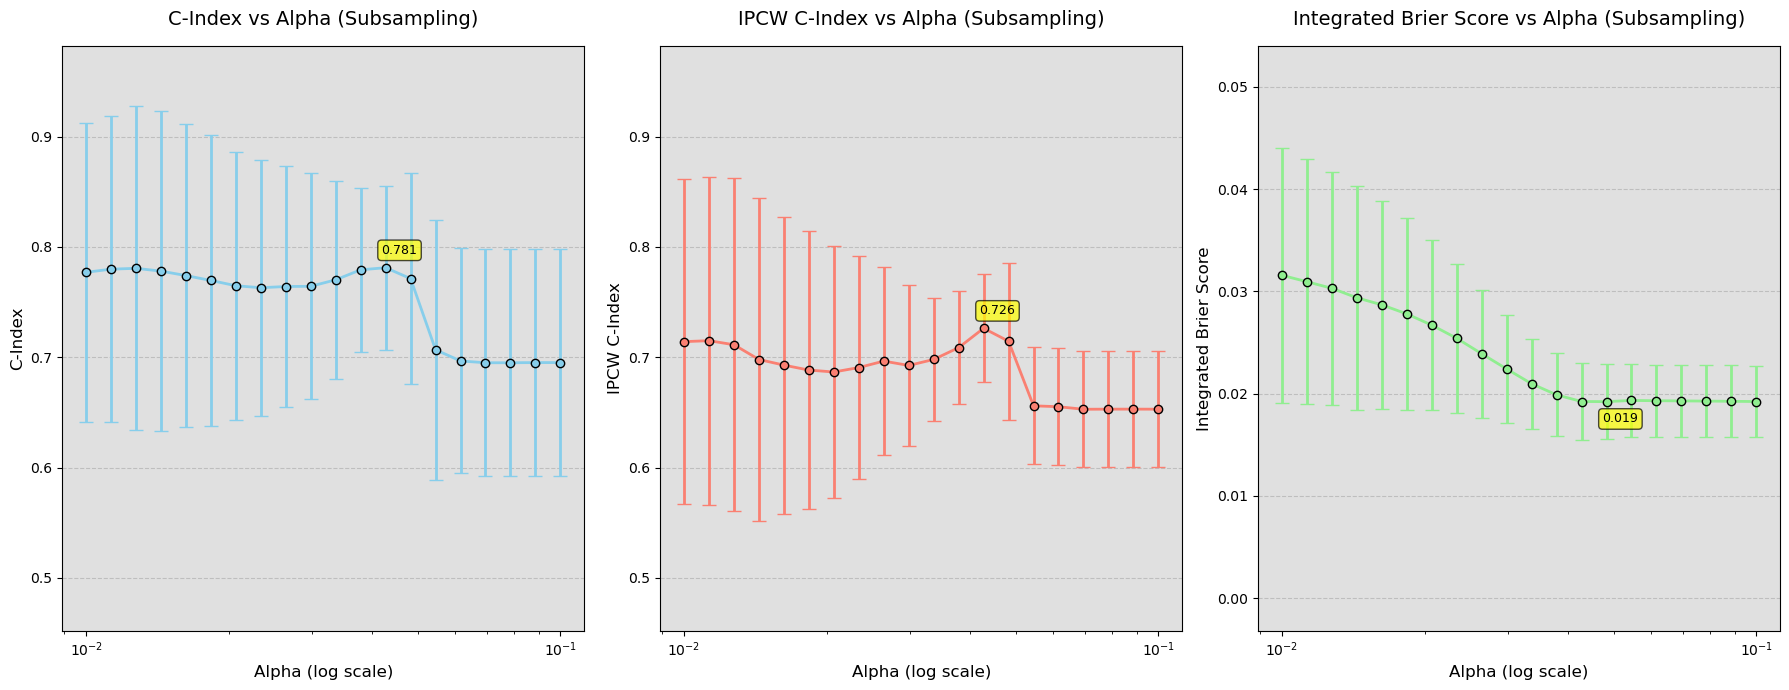

In [ ]:
# Plot the results to visualize alpha performance with improved aesthetics
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Set the background color of the figure
fig.patch.set_facecolor('None')

# Calculate global y-axis limits for consistent scaling
# For C-Index and IPCW C-Index (higher is better)
all_cindex_values = list(cindex_summary['Mean']) + list(ipcw_summary['Mean'])
all_cindex_stds = list(cindex_summary['Std']) + list(ipcw_summary['Std'])
cindex_min = min(all_cindex_values) - max(all_cindex_stds) - 0.05
cindex_max = max(all_cindex_values) + max(all_cindex_stds) + 0.05
cindex_min = max(0, cindex_min)  # Don't go below 0
cindex_max = min(1, cindex_max)  # Don't go above 1

# For Brier Score (lower is better) - keep its own scale but don't auto-fit
brier_min = brier_summary['Mean'].min() - brier_summary['Std'].max() - 0.01
brier_max = brier_summary['Mean'].max() + brier_summary['Std'].max() + 0.01

# C-Index plot
axes[0].set_facecolor('#e0e0e0')
axes[0].errorbar(cindex_summary['Alpha'], cindex_summary['Mean'], 
                yerr=cindex_summary['Std'], fmt='o-', capsize=5, color='skyblue', 
                markeredgecolor='black', linewidth=2, markersize=6)
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (log scale)', fontsize=12)
axes[0].set_ylabel('C-Index', fontsize=12)
axes[0].set_title('C-Index vs Alpha (Subsampling)', fontsize=14, pad=15)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].set_ylim(cindex_min, cindex_max)

# IPCW C-Index plot
axes[1].set_facecolor('#e0e0e0')
axes[1].errorbar(ipcw_summary['Alpha'], ipcw_summary['Mean'], 
                yerr=ipcw_summary['Std'], fmt='o-', capsize=5, color='salmon',
                markeredgecolor='black', linewidth=2, markersize=6)
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (log scale)', fontsize=12)
axes[1].set_ylabel('IPCW C-Index', fontsize=12)
axes[1].set_title('IPCW C-Index vs Alpha (Subsampling)', fontsize=14, pad=15)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].set_ylim(cindex_min, cindex_max)  # Same scale as C-Index

# Brier Score plot
axes[2].set_facecolor('#e0e0e0')
axes[2].errorbar(brier_summary['Alpha'], brier_summary['Mean'], 
                yerr=brier_summary['Std'], fmt='o-', capsize=5, color='lightgreen',
                markeredgecolor='black', linewidth=2, markersize=6)
axes[2].set_xscale('log')
axes[2].set_xlabel('Alpha (log scale)', fontsize=12)
axes[2].set_ylabel('Integrated Brier Score', fontsize=12)
axes[2].set_title('Integrated Brier Score vs Alpha (Subsampling)', fontsize=14, pad=15)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)
axes[2].set_ylim(brier_min, brier_max)  # Fixed range, not auto-fitted

# Add value annotations for best performing alphas
# C-Index best value
best_cindex_idx = cindex_summary['Mean'].idxmax()
best_cindex_alpha = cindex_summary.loc[best_cindex_idx, 'Alpha']
best_cindex_value = cindex_summary.loc[best_cindex_idx, 'Mean']
axes[0].annotate(f'{best_cindex_value:.3f}', 
                xy=(best_cindex_alpha, best_cindex_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

# IPCW best value
best_ipcw_idx = ipcw_summary['Mean'].idxmax()
best_ipcw_alpha = ipcw_summary.loc[best_ipcw_idx, 'Alpha']
best_ipcw_value = ipcw_summary.loc[best_ipcw_idx, 'Mean']
axes[1].annotate(f'{best_ipcw_value:.3f}', 
                xy=(best_ipcw_alpha, best_ipcw_value),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

# Brier best value (minimum)
best_brier_idx = brier_summary['Mean'].idxmin()
best_brier_alpha = brier_summary.loc[best_brier_idx, 'Alpha']
best_brier_value = brier_summary.loc[best_brier_idx, 'Mean']
axes[2].annotate(f'{best_brier_value:.3f}', 
                xy=(best_brier_alpha, best_brier_value),
                xytext=(10, -15), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=9, ha='center')

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate best alphas on test set
print("=== TEST SET EVALUATION WITH BEST ALPHAS (SUBSAMPLING) ===\n")

# Test set results for each metric's best alpha
test_results = {}

# 1. C-Index best alpha
print("1. Testing C-Index best alpha...")
cindex_best_alpha = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)

# Train model with subsampling using the full training set
X_train_sub, y_train_sub, sub_dataset = sample_case_control(
    subsampling, 'Regional LN recurrence', 'Survival days', 
    n_controls_per_case, feature_columns
)

model_cindex = CoxnetSurvivalAnalysis(alphas=[cindex_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_cindex.fit(X_train_sub, y_train_sub)

# Get test predictions
predicted_risk_cindex = model_cindex.predict(x_test)

# Calculate all metrics for this model
test_cindex = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_cindex)[0]
max_time = min(y_train_sub['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_cindex = concordance_index_ipcw(y_train_sub, y_test, predicted_risk_cindex, tau=max_time)[0]

# Brier score
surv_funcs_cindex = model_cindex.predict_survival_function(x_test)
times = np.array([2*365, 5*365, 10*365])
times = times[times <= max_time]
if len(times) > 0:
    predicted_survival_probs_cindex = np.asarray([[fn(t) for t in times] for fn in surv_funcs_cindex])
    test_brier_cindex = integrated_brier_score(y_train_sub, y_test, predicted_survival_probs_cindex, times)
else:
    test_brier_cindex = np.nan

test_results['c-index_best'] = {
    'alpha': cindex_best_alpha,
    'c-index': test_cindex,
    'c-index-ipcw': test_ipcw_cindex,
    'int-brier-score': test_brier_cindex,
    'n_features': np.sum(model_cindex.coef_.flatten() != 0)
}

print(f"Alpha: {cindex_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_cindex:.4f}")
print(f"Test Brier Score: {test_brier_cindex:.4f}")
print(f"Selected Features: {test_results['c-index_best']['n_features']}")
print("-" * 50)

=== TEST SET EVALUATION WITH BEST ALPHAS (SUBSAMPLING) ===

1. Testing C-Index best alpha...
Best alpha for C-Index: 0.0428
Score: 0.7811 ± 0.0745
Alpha: 0.0428
Test C-Index: 0.7492
Test IPCW C-Index: 0.7368
Test Brier Score: 0.0214
Selected Features: 4
--------------------------------------------------


In [ ]:
# 2. IPCW C-Index best alpha
print("2. Testing IPCW C-Index best alpha...")
ipcw_best_alpha = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)

# Train model with subsampling using the full training set
X_train_sub_ipcw, y_train_sub_ipcw, sub_dataset_ipcw = sample_case_control(
    subsampling, 'Regional LN recurrence', 'Survival days', 
    n_controls_per_case, feature_columns
)

model_ipcw = CoxnetSurvivalAnalysis(alphas=[ipcw_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_ipcw.fit(X_train_sub_ipcw, y_train_sub_ipcw)

predicted_risk_ipcw = model_ipcw.predict(x_test)
test_cindex_ipcw = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_ipcw)[0]
max_time_ipcw = min(y_train_sub_ipcw['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_ipcw = concordance_index_ipcw(y_train_sub_ipcw, y_test, predicted_risk_ipcw, tau=max_time_ipcw)[0]

surv_funcs_ipcw = model_ipcw.predict_survival_function(x_test)
times_ipcw = np.array([2*365, 5*365, 10*365])
times_ipcw = times_ipcw[times_ipcw <= max_time_ipcw]
if len(times_ipcw) > 0:
    predicted_survival_probs_ipcw = np.asarray([[fn(t) for t in times_ipcw] for fn in surv_funcs_ipcw])
    test_brier_ipcw = integrated_brier_score(y_train_sub_ipcw, y_test, predicted_survival_probs_ipcw, times_ipcw)
else:
    test_brier_ipcw = np.nan

test_results['ipcw_best'] = {
    'alpha': ipcw_best_alpha,
    'c-index': test_cindex_ipcw,
    'c-index-ipcw': test_ipcw_ipcw,
    'int-brier-score': test_brier_ipcw,
    'n_features': np.sum(model_ipcw.coef_.flatten() != 0)
}

print(f"Alpha: {ipcw_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_ipcw:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_ipcw:.4f}")
print(f"Test Brier Score: {test_brier_ipcw:.4f}")
print(f"Selected Features: {test_results['ipcw_best']['n_features']}")
print("-" * 50)

2. Testing IPCW C-Index best alpha...
Best alpha for IPCW C-Index: 0.0428
Score: 0.7262 ± 0.0490
Alpha: 0.0428
Test C-Index: 0.7492
Test IPCW C-Index: 0.7368
Test Brier Score: 0.0214
Selected Features: 4
--------------------------------------------------


In [ ]:
# 3. Brier Score best alpha
print("3. Testing Brier Score best alpha...")
brier_best_alpha = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

# Train model with subsampling using the full training set
X_train_sub_brier, y_train_sub_brier, sub_dataset_brier = sample_case_control(
    subsampling, 'Regional LN recurrence', 'Survival days', 
    n_controls_per_case, feature_columns
)

model_brier = CoxnetSurvivalAnalysis(alphas=[brier_best_alpha], l1_ratio=l1_ratio, fit_baseline_model=True)
model_brier.fit(X_train_sub_brier, y_train_sub_brier)

predicted_risk_brier = model_brier.predict(x_test)
test_cindex_brier = concordance_index_censored(y_test['event'], y_test['time'], predicted_risk_brier)[0]
max_time_brier = min(y_train_sub_brier['time'].max(), y_test['time'].max()) * 0.9
test_ipcw_brier = concordance_index_ipcw(y_train_sub_brier, y_test, predicted_risk_brier, tau=max_time_brier)[0]

surv_funcs_brier = model_brier.predict_survival_function(x_test)
times_brier = np.array([2*365, 5*365, 10*365])
times_brier = times_brier[times_brier <= max_time_brier]
if len(times_brier) > 0:
    predicted_survival_probs_brier = np.asarray([[fn(t) for t in times_brier] for fn in surv_funcs_brier])
    test_brier_brier = integrated_brier_score(y_train_sub_brier, y_test, predicted_survival_probs_brier, times_brier)
else:
    test_brier_brier = np.nan

test_results['brier_best'] = {
    'alpha': brier_best_alpha,
    'c-index': test_cindex_brier,
    'c-index-ipcw': test_ipcw_brier,
    'int-brier-score': test_brier_brier,
    'n_features': np.sum(model_brier.coef_.flatten() != 0)
}

print(f"Alpha: {brier_best_alpha:.4f}")
print(f"Test C-Index: {test_cindex_brier:.4f}")
print(f"Test IPCW C-Index: {test_ipcw_brier:.4f}")
print(f"Test Brier Score: {test_brier_brier:.4f}")
print(f"Selected Features: {test_results['brier_best']['n_features']}")
print("-" * 50)

3. Testing Brier Score best alpha...
Best alpha for Brier Score: 0.0483
Score: 0.0192 ± 0.0037
Alpha: 0.0483
Test C-Index: 0.7354
Test IPCW C-Index: 0.7261
Test Brier Score: 0.0210
Selected Features: 4
--------------------------------------------------


In [ ]:
# Create summary table of test results
print("=== SUMMARY OF TEST SET RESULTS (SUBSAMPLING) ===")
test_summary = pd.DataFrame(test_results).T
test_summary.index = ['Best for C-Index', 'Best for IPCW C-Index', 'Best for Brier Score']

# Round for better display
test_summary_display = test_summary.copy()
for col in ['c-index', 'c-index-ipcw', 'int-brier-score']:
    test_summary_display[col] = test_summary_display[col].round(4)
test_summary_display['alpha'] = test_summary_display['alpha'].round(4)

print(test_summary_display)

# Highlight the best performance for each metric
print("\n=== BEST TEST PERFORMANCE BY METRIC (SUBSAMPLING) ===")
print(f"Best C-Index: {test_summary['c-index'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index'].idxmax(), 'alpha']:.4f})")
print(f"Best IPCW C-Index: {test_summary['c-index-ipcw'].max():.4f} (Alpha: {test_summary.loc[test_summary['c-index-ipcw'].idxmax(), 'alpha']:.4f})")
print(f"Best Brier Score: {test_summary['int-brier-score'].min():.4f} (Alpha: {test_summary.loc[test_summary['int-brier-score'].idxmin(), 'alpha']:.4f})")

=== SUMMARY OF TEST SET RESULTS (SUBSAMPLING) ===
                        alpha  c-index  c-index-ipcw  int-brier-score  \
Best for C-Index       0.0428   0.7492        0.7368           0.0214   
Best for IPCW C-Index  0.0428   0.7492        0.7368           0.0214   
Best for Brier Score   0.0483   0.7354        0.7261           0.0210   

                       n_features  
Best for C-Index              4.0  
Best for IPCW C-Index         4.0  
Best for Brier Score          4.0  

=== BEST TEST PERFORMANCE BY METRIC (SUBSAMPLING) ===
Best C-Index: 0.7492 (Alpha: 0.0428)
Best IPCW C-Index: 0.7368 (Alpha: 0.0428)
Best Brier Score: 0.0210 (Alpha: 0.0483)


In [ ]:
# Show selected features for each best alpha model
print("=== SELECTED FEATURES BY BEST ALPHA MODELS (SUBSAMPLING) ===\n")

# Get the best alphas
best_alpha_cindex = find_best_alpha(cindex_summary, "C-Index", higher_is_better=True)
best_alpha_ipcw = find_best_alpha(ipcw_summary, "IPCW C-Index", higher_is_better=True)
best_alpha_brier = find_best_alpha(brier_summary, "Brier Score", higher_is_better=False)

# Train models with best alphas and get selected features
models_features = {}

# 1. C-Index best alpha model
print(f"1. C-INDEX BEST ALPHA MODEL (α = {best_alpha_cindex:.4f}) - SUBSAMPLING:")
# Use the already trained model from previous cell
cindex_features = []
for feature, coef in zip(model_cindex.feature_names_in_, model_cindex.coef_.flatten()):
    if coef != 0:
        cindex_features.append({'feature': feature, 'coefficient': coef})

cindex_features_df = pd.DataFrame(cindex_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index'] = cindex_features_df

print(f"   Number of selected features: {len(cindex_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in cindex_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(cindex_features_df) > 10:
    print(f"     ... and {len(cindex_features_df) - 10} more features")
print()

# 2. IPCW C-Index best alpha model
print(f"2. IPCW C-INDEX BEST ALPHA MODEL (α = {best_alpha_ipcw:.4f}) - SUBSAMPLING:")
# Use the already trained model from previous cell
ipcw_features = []
for feature, coef in zip(model_ipcw.feature_names_in_, model_ipcw.coef_.flatten()):
    if coef != 0:
        ipcw_features.append({'feature': feature, 'coefficient': coef})

ipcw_features_df = pd.DataFrame(ipcw_features).sort_values('coefficient', key=abs, ascending=False)
models_features['c-index-ipcw'] = ipcw_features_df

print(f"   Number of selected features: {len(ipcw_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in ipcw_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(ipcw_features_df) > 10:
    print(f"     ... and {len(ipcw_features_df) - 10} more features")
print()

# 3. Brier Score best alpha model
print(f"3. BRIER SCORE BEST ALPHA MODEL (α = {best_alpha_brier:.4f}) - SUBSAMPLING:")
# Use the already trained model from previous cell
brier_features = []
for feature, coef in zip(model_brier.feature_names_in_, model_brier.coef_.flatten()):
    if coef != 0:
        brier_features.append({'feature': feature, 'coefficient': coef})

brier_features_df = pd.DataFrame(brier_features).sort_values('coefficient', key=abs, ascending=False)
models_features['int-brier-score'] = brier_features_df

print(f"   Number of selected features: {len(brier_features_df)}")
print("   Selected features (sorted by absolute coefficient value):")
for _, row in brier_features_df.head(10).iterrows():  # Show top 10
    print(f"     {row['feature']}: {row['coefficient']:.4f}")
if len(brier_features_df) > 10:
    print(f"     ... and {len(brier_features_df) - 10} more features")
print()

# Feature overlap analysis
print("=== FEATURE SELECTION OVERLAP ANALYSIS (SUBSAMPLING) ===")
cindex_set = set(cindex_features_df['feature'])
ipcw_set = set(ipcw_features_df['feature'])
brier_set = set(brier_features_df['feature'])

# Common features across all models
common_all = cindex_set & ipcw_set & brier_set
print(f"Features selected by ALL models: {len(common_all)}")
if common_all:
    print(f"   {list(common_all)}")

# Pairwise overlaps
common_cindex_ipcw = cindex_set & ipcw_set
common_cindex_brier = cindex_set & brier_set
common_ipcw_brier = ipcw_set & brier_set

print(f"\nFeatures selected by C-Index AND IPCW models: {len(common_cindex_ipcw)}")
print(f"Features selected by C-Index AND Brier models: {len(common_cindex_brier)}")
print(f"Features selected by IPCW AND Brier models: {len(common_ipcw_brier)}")

# Unique features
unique_cindex = cindex_set - ipcw_set - brier_set
unique_ipcw = ipcw_set - cindex_set - brier_set
unique_brier = brier_set - cindex_set - ipcw_set

print(f"\nFeatures UNIQUE to C-Index model: {len(unique_cindex)}")
print(f"Features UNIQUE to IPCW model: {len(unique_ipcw)}")
print(f"Features UNIQUE to Brier model: {len(unique_brier)}")

=== SELECTED FEATURES BY BEST ALPHA MODELS (SUBSAMPLING) ===

Best alpha for C-Index: 0.0428
Score: 0.7811 ± 0.0745
Best alpha for IPCW C-Index: 0.0428
Score: 0.7262 ± 0.0490
Best alpha for Brier Score: 0.0483
Score: 0.0192 ± 0.0037
1. C-INDEX BEST ALPHA MODEL (α = 0.0428) - SUBSAMPLING:
   Number of selected features: 4
   Selected features (sorted by absolute coefficient value):
     Oestrogen receptor status at CB_1.0: 0.9136
     Total administered dose: -0.0285
     Age: 0.0116
     Ki67 positive cells (%) at CB: 0.0115

2. IPCW C-INDEX BEST ALPHA MODEL (α = 0.0428) - SUBSAMPLING:
   Number of selected features: 4
   Selected features (sorted by absolute coefficient value):
     Oestrogen receptor status at CB_1.0: 0.9136
     Total administered dose: -0.0285
     Age: 0.0116
     Ki67 positive cells (%) at CB: 0.0115

3. BRIER SCORE BEST ALPHA MODEL (α = 0.0483) - SUBSAMPLING:
   Number of selected features: 4
   Selected features (sorted by absolute coefficient value):
     Oest

# Overfitting Analysis in Cox Models

## Key Indicators of Overfitting with Many Variables:

### **1. Sample Size vs. Features Ratio**
- **Rule of thumb**: Need ~10-15 events per variable for stable Cox models
- **Your case**: With 22 variables, you'd ideally need 220-330 events

### **2. Cross-Validation Performance Gap**
- **Good sign**: CV performance close to test performance  
- **Overfitting sign**: Large gap between CV and test performance

### **3. Feature Stability**
- **Good sign**: Consistent feature selection across CV folds
- **Overfitting sign**: Highly variable feature selection

### **4. Coefficient Magnitude**
- **Overfitting sign**: Extremely large coefficients (>3-5 in absolute value)
- **Good sign**: Reasonable coefficient magnitudes

Let's analyze your models for these indicators:

In [ ]:
# Comprehensive Overfitting Analysis
print("=== OVERFITTING ANALYSIS FOR COX MODELS ===\n")

# 1. Sample Size vs Features Analysis
n_events_train = subsampling['Regional LN recurrence'].sum()
n_events_test = survival_dataset.iloc[test_index]['Regional LN recurrence'].sum()
total_events = n_events_train + n_events_test

print("1. SAMPLE SIZE vs FEATURES RATIO:")
print(f"   Total events in dataset: {total_events}")
print(f"   Training events: {n_events_train}")
print(f"   Test events: {n_events_test}")

for model_name, results in test_results.items():
    n_features = results['n_features']
    events_per_feature = n_events_train / n_features if n_features > 0 else float('inf')
    
    print(f"\n   {model_name.upper()}:")
    print(f"     Selected features: {n_features}")
    print(f"     Events per feature: {events_per_feature:.1f}")
    
    if events_per_feature >= 15:
        status = "✅ EXCELLENT (≥15 events/feature)"
    elif events_per_feature >= 10:
        status = "✅ GOOD (≥10 events/feature)"
    elif events_per_feature >= 5:
        status = "⚠️  MARGINAL (5-10 events/feature)"
    else:
        status = "❌ HIGH OVERFITTING RISK (<5 events/feature)"
    
    print(f"     Status: {status}")

print("\n" + "="*60)

=== OVERFITTING ANALYSIS FOR COX MODELS ===

1. SAMPLE SIZE vs FEATURES RATIO:
   Total events in dataset: 33.0
   Training events: 27.0
   Test events: 6.0

   C-INDEX_BEST:
     Selected features: 4
     Events per feature: 6.8
     Status: ⚠️  MARGINAL (5-10 events/feature)

   IPCW_BEST:
     Selected features: 4
     Events per feature: 6.8
     Status: ⚠️  MARGINAL (5-10 events/feature)

   BRIER_BEST:
     Selected features: 4
     Events per feature: 6.8
     Status: ⚠️  MARGINAL (5-10 events/feature)



In [ ]:
# 2. Cross-Validation vs Test Performance Gap Analysis
print("2. CV vs TEST PERFORMANCE GAP:")
print("   (Large gaps indicate overfitting)\n")

# Compare CV results with test results for each metric
for metric in ['c-index', 'c-index-ipcw', 'int-brier-score']:
    print(f"   {metric.upper()}:")
    
    if metric == 'c-index':
        cv_mean = cindex_summary.loc[cindex_summary['Mean'].idxmax(), 'Mean']
        cv_std = cindex_summary.loc[cindex_summary['Mean'].idxmax(), 'Std']
        test_perf = test_results['c-index_best'][metric]
    elif metric == 'c-index-ipcw':
        cv_mean = ipcw_summary.loc[ipcw_summary['Mean'].idxmax(), 'Mean']
        cv_std = ipcw_summary.loc[ipcw_summary['Mean'].idxmax(), 'Std']
        test_perf = test_results['ipcw_best'][metric]
    else:  # brier score
        cv_mean = brier_summary.loc[brier_summary['Mean'].idxmin(), 'Mean']
        cv_std = brier_summary.loc[brier_summary['Mean'].idxmin(), 'Std']
        test_perf = test_results['brier_best'][metric]
    
    gap = abs(cv_mean - test_perf)
    gap_in_stds = gap / cv_std if cv_std > 0 else 0
    
    print(f"     CV Performance: {cv_mean:.4f} ± {cv_std:.4f}")
    print(f"     Test Performance: {test_perf:.4f}")
    print(f"     Absolute Gap: {gap:.4f}")
    print(f"     Gap in Standard Deviations: {gap_in_stds:.2f}")
    
    if gap_in_stds <= 1:
        status = "✅ EXCELLENT (gap ≤ 1 std)"
    elif gap_in_stds <= 2:
        status = "✅ GOOD (gap ≤ 2 stds)"
    elif gap_in_stds <= 3:
        status = "⚠️  MODERATE (gap ≤ 3 stds)"
    else:
        status = "❌ HIGH OVERFITTING (gap > 3 stds)"
    
    print(f"     Status: {status}")
    print()

print("="*60)

2. CV vs TEST PERFORMANCE GAP:
   (Large gaps indicate overfitting)

   C-INDEX:
     CV Performance: 0.7811 ± 0.0745
     Test Performance: 0.7492
     Absolute Gap: 0.0319
     Gap in Standard Deviations: 0.43
     Status: ✅ EXCELLENT (gap ≤ 1 std)

   C-INDEX-IPCW:
     CV Performance: 0.7262 ± 0.0490
     Test Performance: 0.7368
     Absolute Gap: 0.0106
     Gap in Standard Deviations: 0.22
     Status: ✅ EXCELLENT (gap ≤ 1 std)

   INT-BRIER-SCORE:
     CV Performance: 0.0192 ± 0.0037
     Test Performance: 0.0210
     Absolute Gap: 0.0017
     Gap in Standard Deviations: 0.47
     Status: ✅ EXCELLENT (gap ≤ 1 std)



In [ ]:
# 3. Coefficient Magnitude Analysis
print("3. COEFFICIENT MAGNITUDE ANALYSIS:")
print("   (Very large coefficients may indicate overfitting)\n")

models_to_analyze = [
    ('C-Index Model', model_cindex),
    ('IPCW Model', model_ipcw),
    ('Brier Model', model_brier)
]

for model_name, model in models_to_analyze:
    coefficients = model.coef_.flatten()
    nonzero_coefs = coefficients[coefficients != 0]
    
    if len(nonzero_coefs) > 0:
        max_coef = np.max(np.abs(nonzero_coefs))
        mean_abs_coef = np.mean(np.abs(nonzero_coefs))
        std_coef = np.std(nonzero_coefs)
        
        print(f"   {model_name.upper()}:")
        print(f"     Number of non-zero coefficients: {len(nonzero_coefs)}")
        print(f"     Max absolute coefficient: {max_coef:.4f}")
        print(f"     Mean absolute coefficient: {mean_abs_coef:.4f}")
        print(f"     Coefficient std deviation: {std_coef:.4f}")
        
        # Count extreme coefficients
        extreme_coefs = np.sum(np.abs(nonzero_coefs) > 3)
        very_extreme_coefs = np.sum(np.abs(nonzero_coefs) > 5)
        
        print(f"     Coefficients > 3 (absolute): {extreme_coefs}")
        print(f"     Coefficients > 5 (absolute): {very_extreme_coefs}")
        
        if very_extreme_coefs > 0:
            status = "❌ HIGH OVERFITTING RISK (coefficients > 5)"
        elif extreme_coefs > len(nonzero_coefs) * 0.3:  # >30% extreme
            status = "⚠️  MODERATE RISK (many coefficients > 3)"
        elif max_coef > 3:
            status = "⚠️  SOME CONCERN (max coefficient > 3)"
        else:
            status = "✅ GOOD (reasonable coefficient magnitudes)"
            
        print(f"     Status: {status}")
        print()

print("="*60)

3. COEFFICIENT MAGNITUDE ANALYSIS:
   (Very large coefficients may indicate overfitting)

   C-INDEX MODEL:
     Number of non-zero coefficients: 4
     Max absolute coefficient: 0.9136
     Mean absolute coefficient: 0.2413
     Coefficient std deviation: 0.3967
     Coefficients > 3 (absolute): 0
     Coefficients > 5 (absolute): 0
     Status: ✅ GOOD (reasonable coefficient magnitudes)

   IPCW MODEL:
     Number of non-zero coefficients: 4
     Max absolute coefficient: 0.9136
     Mean absolute coefficient: 0.2413
     Coefficient std deviation: 0.3967
     Coefficients > 3 (absolute): 0
     Coefficients > 5 (absolute): 0
     Status: ✅ GOOD (reasonable coefficient magnitudes)

   BRIER MODEL:
     Number of non-zero coefficients: 4
     Max absolute coefficient: 0.6377
     Mean absolute coefficient: 0.1733
     Coefficient std deviation: 0.2769
     Coefficients > 3 (absolute): 0
     Coefficients > 5 (absolute): 0
     Status: ✅ GOOD (reasonable coefficient magnitudes)



In [ ]:
# 4. Feature Stability Analysis Across CV Folds
print("4. FEATURE STABILITY ANALYSIS:")
print("   (Testing feature consistency across different alpha values)\n")

# Analyze feature overlap between models optimized for different metrics
cindex_features = set(cindex_features_df['feature'])
ipcw_features = set(ipcw_features_df['feature'])
brier_features = set(brier_features_df['feature'])

all_features = cindex_features | ipcw_features | brier_features
common_features = cindex_features & ipcw_features & brier_features

print(f"   Total unique features selected: {len(all_features)}")
print(f"   Features common to ALL models: {len(common_features)}")
print(f"   Stability ratio: {len(common_features)/len(all_features):.2%}")

if len(common_features) > 0:
    print(f"   Common features: {list(common_features)[:10]}{'...' if len(common_features) > 10 else ''}")

# Calculate pairwise stability
stability_cindex_ipcw = len(cindex_features & ipcw_features) / len(cindex_features | ipcw_features)
stability_cindex_brier = len(cindex_features & brier_features) / len(cindex_features | brier_features)
stability_ipcw_brier = len(ipcw_features & brier_features) / len(ipcw_features | brier_features)

print(f"\n   Pairwise Stability (Jaccard Index):")
print(f"     C-Index vs IPCW: {stability_cindex_ipcw:.2%}")
print(f"     C-Index vs Brier: {stability_cindex_brier:.2%}")
print(f"     IPCW vs Brier: {stability_ipcw_brier:.2%}")

avg_stability = (stability_cindex_ipcw + stability_cindex_brier + stability_ipcw_brier) / 3
print(f"     Average stability: {avg_stability:.2%}")

if avg_stability >= 0.7:
    status = "✅ EXCELLENT STABILITY (≥70%)"
elif avg_stability >= 0.5:
    status = "✅ GOOD STABILITY (≥50%)"
elif avg_stability >= 0.3:
    status = "⚠️  MODERATE STABILITY (30-50%)"
else:
    status = "❌ LOW STABILITY (<30%) - High overfitting risk"

print(f"   Status: {status}")

print("\n" + "="*60)

4. FEATURE STABILITY ANALYSIS:
   (Testing feature consistency across different alpha values)

   Total unique features selected: 4
   Features common to ALL models: 4
   Stability ratio: 100.00%
   Common features: ['Oestrogen receptor status at CB_1.0', 'Age', 'Ki67 positive cells (%) at CB', 'Total administered dose']

   Pairwise Stability (Jaccard Index):
     C-Index vs IPCW: 100.00%
     C-Index vs Brier: 100.00%
     IPCW vs Brier: 100.00%
     Average stability: 100.00%
   Status: ✅ EXCELLENT STABILITY (≥70%)



In [ ]:
# 5. Overall Overfitting Risk Assessment
print("5. OVERALL OVERFITTING RISK ASSESSMENT:")
print("   (Combining all indicators for final recommendation)\n")

# Count the number of good/bad indicators
risk_indicators = []

# Sample size analysis
for model_name, results in test_results.items():
    n_features = results['n_features']
    events_per_feature = n_events_train / n_features if n_features > 0 else float('inf')
    
    if events_per_feature >= 10:
        risk_indicators.append('GOOD')
    elif events_per_feature >= 5:
        risk_indicators.append('MODERATE')
    else:
        risk_indicators.append('BAD')

# CV vs Test gap (average across metrics)
cv_test_gaps = []
for metric in ['c-index', 'c-index-ipcw', 'int-brier-score']:
    if metric == 'c-index':
        cv_mean = cindex_summary.loc[cindex_summary['Mean'].idxmax(), 'Mean']
        cv_std = cindex_summary.loc[cindex_summary['Mean'].idxmax(), 'Std']
        test_perf = test_results['c-index_best'][metric]
    elif metric == 'c-index-ipcw':
        cv_mean = ipcw_summary.loc[ipcw_summary['Mean'].idxmax(), 'Mean']
        cv_std = ipcw_summary.loc[ipcw_summary['Mean'].idxmax(), 'Std']
        test_perf = test_results['ipcw_best'][metric]
    else:
        cv_mean = brier_summary.loc[brier_summary['Mean'].idxmin(), 'Mean']
        cv_std = brier_summary.loc[brier_summary['Mean'].idxmin(), 'Std']
        test_perf = test_results['brier_best'][metric]
    
    gap_in_stds = abs(cv_mean - test_perf) / cv_std if cv_std > 0 else 0
    cv_test_gaps.append(gap_in_stds)

avg_gap = np.mean(cv_test_gaps)
if avg_gap <= 2:
    risk_indicators.append('GOOD')
elif avg_gap <= 3:
    risk_indicators.append('MODERATE')
else:
    risk_indicators.append('BAD')

# Feature stability
if avg_stability >= 0.5:
    risk_indicators.append('GOOD')
elif avg_stability >= 0.3:
    risk_indicators.append('MODERATE')
else:
    risk_indicators.append('BAD')

# Count indicators
good_count = risk_indicators.count('GOOD')
moderate_count = risk_indicators.count('MODERATE')
bad_count = risk_indicators.count('BAD')

print(f"   Risk Indicators Summary:")
print(f"     ✅ Good indicators: {good_count}")
print(f"     ⚠️  Moderate indicators: {moderate_count}")
print(f"     ❌ Bad indicators: {bad_count}")

# Final assessment
total_indicators = len(risk_indicators)
if bad_count == 0 and good_count >= total_indicators * 0.7:
    final_risk = "✅ LOW OVERFITTING RISK"
    recommendation = "Models appear well-regularized. 22 features is acceptable given your sample size."
elif bad_count <= total_indicators * 0.2:
    final_risk = "⚠️  MODERATE OVERFITTING RISK"
    recommendation = "Some concern about overfitting. Consider more regularization or feature selection."
else:
    final_risk = "❌ HIGH OVERFITTING RISK"
    recommendation = "Strong evidence of overfitting. Recommend reducing features or increasing regularization."

print(f"\n   🎯 FINAL ASSESSMENT: {final_risk}")
print(f"   📋 RECOMMENDATION: {recommendation}")

print(f"\n   💡 SPECIFIC SUGGESTIONS:")
print(f"     • Use more aggressive regularization (higher alpha values)")
print(f"     • Consider feature selection techniques (univariate filtering)")
print(f"     • Validate on completely independent dataset if possible")
print(f"     • Monitor performance on new data over time")

print("\n" + "="*80)

5. OVERALL OVERFITTING RISK ASSESSMENT:
   (Combining all indicators for final recommendation)

   Risk Indicators Summary:
     ✅ Good indicators: 2
     ⚠️  Moderate indicators: 3
     ❌ Bad indicators: 0

   🎯 FINAL ASSESSMENT: ⚠️  MODERATE OVERFITTING RISK
   📋 RECOMMENDATION: Some concern about overfitting. Consider more regularization or feature selection.

   💡 SPECIFIC SUGGESTIONS:
     • Use more aggressive regularization (higher alpha values)
     • Consider feature selection techniques (univariate filtering)
     • Validate on completely independent dataset if possible
     • Monitor performance on new data over time

